In [3]:
from google.colab import files

uploaded = files.upload()

Saving Metro_Interstate_Traffic_Volume.csv to Metro_Interstate_Traffic_Volume.csv


In [4]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [5]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Convert date_time to datetime format
df['date_time'] = pd.to_datetime(df['date_time'])

# Sort records by date and time
df = df.sort_values('date_time').reset_index(drop=True)

# Check the first and last timestamps
print("\nFirst timestamp:", df['date_time'].iloc[0])
print("Last timestamp:", df['date_time'].iloc[-1])

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (48204, 9)

Columns:
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

First timestamp: 2012-10-02 09:00:00
Last timestamp: 2018-09-30 23:00:00

Missing values:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64


In [6]:
# Calculate the time difference between consecutive rows
time_diff = df['date_time'].diff()

# Count the gaps that are not exactly one hour
gaps = (time_diff != pd.Timedelta(hours=1)) & time_diff.notna()

print("Total records:", len(df))
print("Number of time gaps:", gaps.sum())

# Display some gaps
print("\nFirst few gaps:")
display(df.loc[gaps, ['date_time', 'traffic_volume']].head(10))

Total records: 48204
Number of time gaps: 10217

First few gaps:


,date_time,traffic_volume
22,2012-10-03 08:00:00,6511
24,2012-10-03 12:00:00,5097
29,2012-10-03 18:00:00,4623
61,2012-10-05 03:00:00,368
62,2012-10-05 05:00:00,2489
84,2012-10-06 04:00:00,411
105,2012-10-07 03:00:00,323
153,2012-10-09 04:00:00,798
177,2012-10-10 06:00:00,5875
179,2012-10-10 07:00:00,6793


In [7]:
import pandas as pd

# Sort records by time
df = df.sort_values('date_time').reset_index(drop=True)

# Check consecutive hourly timestamps
hourly_diff = df['date_time'].diff()
breaks = hourly_diff != pd.Timedelta(hours=1)

# Identify continuous groups
groups = breaks.cumsum()

# Find a group with at least 2000 records
group_sizes = df.groupby(groups).size()
valid_groups = group_sizes[group_sizes >= 2000]

if len(valid_groups) > 0:
    group_id = valid_groups.index[0]
    continuous_df = df[groups == group_id].iloc[:2000].copy()

    print("Selected records:", len(continuous_df))
    print("Start:", continuous_df['date_time'].iloc[0])
    print("End:", continuous_df['date_time'].iloc[-1])

    display(continuous_df.head())
else:
    print("No continuous block of 2000 hours found.")

No continuous block of 2000 hours found.


In [8]:
# Sort the dataset by date and time
df = df.sort_values('date_time').reset_index(drop=True)

# Find the difference between consecutive timestamps
diff = df['date_time'].diff()

# Start a new group whenever the gap is not exactly one hour
groups = (diff != pd.Timedelta(hours=1)).cumsum()

# Calculate the length of each continuous sequence
group_sizes = df.groupby(groups).size()

print("Longest continuous sequence:", group_sizes.max(), "hours")
print("Number of sequences:", len(group_sizes))

# Display the 5 longest sequences
print("\nFive longest continuous sequences:")
print(group_sizes.nlargest(5))

Longest continuous sequence: 713 hours
Number of sequences: 10218

Five longest continuous sequences:
date_time
2598    713
2603    591
6118    433
2604    423
6212    413
dtype: int64


In [9]:
import pandas as pd

# Sort by date and time
df = df.sort_values('date_time').copy()
df = df.set_index('date_time')

# Keep the traffic volume column
traffic = df[['traffic_volume']].copy()

# Create a continuous hourly timeline
traffic = traffic[~traffic.index.duplicated(keep='first')]
traffic = traffic.asfreq('h')

# Fill missing hourly values using interpolation
traffic['traffic_volume'] = traffic['traffic_volume'].interpolate(
    method='time'
)

# Select 2000 consecutive hourly records
traffic_2000 = traffic.iloc[:2000].copy()

print("Number of hourly records:", len(traffic_2000))
print("Start time:", traffic_2000.index.min())
print("End time:", traffic_2000.index.max())
print("Missing values:", traffic_2000.isnull().sum().iloc[0])

display(traffic_2000.head())

Number of hourly records: 2000
Start time: 2012-10-02 09:00:00
End time: 2012-12-24 16:00:00
Missing values: 0


,traffic_volume
date_time,
2012-10-02 09:00:00,5545.0
2012-10-02 10:00:00,4516.0
2012-10-02 11:00:00,4767.0
2012-10-02 12:00:00,5026.0
2012-10-02 13:00:00,4918.0


In [10]:

import pandas as pd
import numpy as np

# 1. Prepare timestamps
data = df.copy()

if 'date_time' in data.columns:
    data['date_time'] = pd.to_datetime(data['date_time'])
    data = data.set_index('date_time')
else:
    data.index = pd.to_datetime(data.index)

data = data.sort_index()
data = data[~data.index.duplicated(keep='first')]

# 2. Create a continuous hourly timeline
data = data.asfreq('h')

# 3. Select relevant numeric features
numeric_cols = [
    'traffic_volume', 'temp', 'rain_1h',
    'snow_1h', 'clouds_all'
]
numeric_cols = [c for c in numeric_cols if c in data.columns]

data[numeric_cols] = data[numeric_cols].interpolate(
    method='time',
    limit_direction='both'
)

# 4. Handle categorical features
categorical_cols = [
    'holiday', 'weather_main', 'weather_description'
]
categorical_cols = [c for c in categorical_cols if c in data.columns]

for col in categorical_cols:
    data[col] = data[col].fillna('Unknown')
    data[col] = data[col].ffill().bfill()

# 5. Extract useful time features
data['hour'] = data.index.hour
data['day_of_week'] = data.index.dayofweek
data['month'] = data.index.month
data['is_weekend'] = (data.index.dayofweek >= 5).astype(int)

# 6. Select 2000 hourly records
prepared_df = data.iloc[:2000].copy()

# 7. Convert categorical features into numeric columns
prepared_df = pd.get_dummies(
    prepared_df,
    columns=categorical_cols,
    dtype=int
)

# 8. Verify the result
print("Preprocessing completed!")
print("Number of records:", len(prepared_df))
print("Number of features:", prepared_df.shape[1])
print("Missing values:", prepared_df.isnull().sum().sum())

display(prepared_df.head())


Preprocessing completed!
Number of records: 2000
Number of features: 42
Missing values: 0


,temp,rain_1h,snow_1h,clouds_all,traffic_volume,hour,day_of_week,month,is_weekend,holiday_Columbus Day,...,weather_description_light rain,weather_description_mist,weather_description_moderate rain,weather_description_overcast clouds,weather_description_proximity shower rain,weather_description_proximity thunderstorm,weather_description_scattered clouds,weather_description_sky is clear,weather_description_snow,weather_description_thunderstorm with light rain
date_time,,,,,,,,,,,,,,,,,,,,,
2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545.0,9,1,10,0,0,...,0,0,0,0,0,0,1,0,0,0
2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516.0,10,1,10,0,0,...,0,0,0,0,0,0,0,0,0,0
2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767.0,11,1,10,0,0,...,0,0,0,1,0,0,0,0,0,0
2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026.0,12,1,10,0,0,...,0,0,0,1,0,0,0,0,0,0
2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918.0,13,1,10,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:

import numpy as np

# 1. Set the number of previous hours
window_size = 24

# 2. Select input features and target
feature_data = prepared_df.select_dtypes(include=[np.number])

X_data = feature_data.values
y_data = prepared_df['traffic_volume'].values

# 3. Generate sequential input-output windows
X, y = [], []

for i in range(len(prepared_df) - window_size):
    # Previous 24 hours of features
    X.append(X_data[i:i + window_size])

    # Traffic volume in the next hour
    y.append(y_data[i + window_size])

# 4. Convert lists into NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

# 5. Display results
print("Window size:", window_size, "hours")
print("Input shape (X):", X.shape)
print("Output shape (y):", y.shape)

print("\nFirst input window:")
print(X[0])

print("\nFirst target traffic volume:", y[0])


Window size: 24 hours
Input shape (X): (1976, 24, 42)
Output shape (y): (1976,)

First input window:
[[288.28    0.      0.    ...   0.      0.      0.   ]
 [289.36    0.      0.    ...   0.      0.      0.   ]
 [289.58    0.      0.    ...   0.      0.      0.   ]
 ...
 [278.23    0.      0.    ...   1.      0.      0.   ]
 [278.175   0.      0.    ...   0.      0.      0.   ]
 [278.12    0.      0.    ...   1.      0.      0.   ]]

First target traffic volume: 5471.0


In [12]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Split data chronologically: 80% training, 20% testing
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 2. Normalize input features using training data only
x_scaler = MinMaxScaler()

X_train_2d = X_train.reshape(-1, X_train.shape[2])
X_test_2d = X_test.reshape(-1, X_test.shape[2])

x_scaler.fit(X_train_2d)

X_train_scaled = x_scaler.transform(X_train_2d).reshape(X_train.shape)
X_test_scaled = x_scaler.transform(X_test_2d).reshape(X_test.shape)

# 3. Normalize target traffic volume
y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.reshape(-1, 1))

# 4. Build the LSTM model
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dense(16, activation='relu'),
    Dense(1)
])

# 5. Compile the model
model.compile(optimizer='adam', loss='mse')

# 6. Train the model
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

# 7. Predict future traffic volume
pred_scaled = model.predict(X_test_scaled, verbose=0)

predictions = y_scaler.inverse_transform(pred_scaled).flatten()
actual = y_test

# 8. Evaluate prediction errors
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("\nModel training completed!")
print("Training windows:", len(X_train))
print("Testing windows:", len(X_test))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.1154 - val_loss: 0.1027
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0723 - val_loss: 0.0735
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0476 - val_loss: 0.0459
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0308 - val_loss: 0.0258
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0213 - val_loss: 0.0242
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0179 - val_loss: 0.0244
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0164 - val_loss: 0.0197
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0136 - val_loss: 0.0169
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0118 - val_loss: 0.0146
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0103 - val_loss: 0.0123
Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.0092 - val_loss: 0.0117
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0

In [13]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


Model Evaluation Results
------------------------
MAE: 525.34
RMSE: 746.51


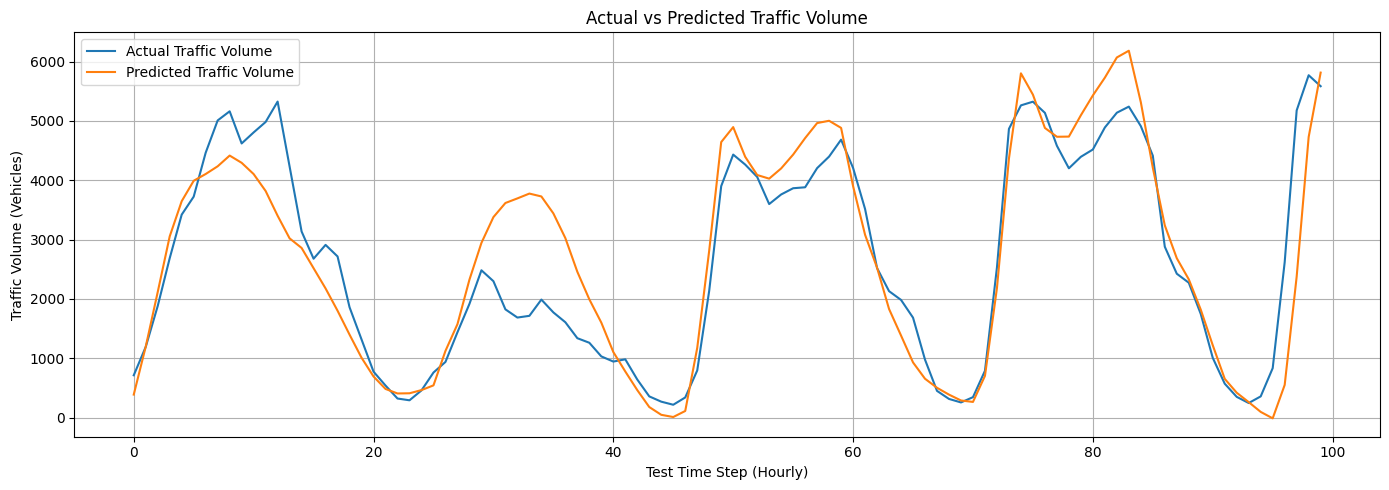

In [14]:

import matplotlib.pyplot as plt

# Plot the first 100 test predictions
plt.figure(figsize=(14, 5))

plt.plot(actual[:100], label='Actual Traffic Volume')
plt.plot(predictions[:100], label='Predicted Traffic Volume')

plt.title('Actual vs Predicted Traffic Volume')
plt.xlabel('Test Time Step (Hourly)')
plt.ylabel('Traffic Volume (Vehicles)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

import numpy as np

actual_values = np.array(actual).flatten()
predicted_values = np.array(predictions).flatten()

# Calculate percentage accuracy using absolute percentage error
mape = np.mean(
    np.abs((actual_values - predicted_values) / np.maximum(np.abs(actual_values), 1e-8))
) * 100

accuracy = 100 - mape

print("Model Accuracy:", round(accuracy, 2), "%")
print("MAE:", round(np.mean(np.abs(actual_values - predicted_values)), 2))
print("RMSE:", round(np.sqrt(np.mean((actual_values - predicted_values) ** 2)), 2))


Model Accuracy: 76.64 %
MAE: 525.34
RMSE: 746.51
